# Data VZP: kdy žena přijde na mamograf po pozvánce

**Finální model:** diskrétní model přežití (hazard), každá žena váží stejně, pásma jako pořadová čísla.

Data hackathonu (`data_vzp/Rakhaton2026.csv.gz`, popis v `data_vzp/Rakathon_Datove_rozhrani.md`):
1 344 556 adresných pozvánek 2020–2024 pro 508 527 žen pojištěných u VZP nepřetržitě 2015–2025.

* **Hazard.** Jeden CatBoost model odhaduje šanci h_k, že žena přijde v intervalu 0–3, 3–6 nebo
  6–12 měsíců po pozvánce, pokud nepřišla dřív. Účast do konce intervalu k je 1 − ∏(1 − h_j), takže
  předpovědi pro 3, 6 a 12 měsíců jsou vždy konzistentní.
* **Na ženu.** Žena má v datech až 5 pozvánek. Učení i vyhodnocení váží každou pozvánku
  1 / počet pozvánek ženy (v dané části dat), takže každá žena váží stejně; intervaly spolehlivosti
  převzorkovávají ženy, ne řádky.
* **Pořadová pásma.** Věk = dolní mez pásma (40, 45, …, 70), registrace u praktika a gynekologa
  0 = žádná, 1 = <2 roky, 2 = 2–5 let, 3 = >5 let. Jedinou kategorií je územní pracoviště VZP.

Předchozí kroky: `vzp_catboost_shap.ipynb` (tři samostatné modely, kontroly opakovaných pozvánek)
a `vzp_hazard.ipynb` (hazard na pozvánku, srovnání pořadových a kategoriálních pásem: shodné AUROC).
Notebook ukazuje jen agregáty, žádné řádky jednotlivých žen.

## Hlavní zjištění

1. **Na pozvánku vs. na ženu.** Do 3 / 6 / 12 měsíců vede k mamografii 7,1 / 12,5 / 19,3 % pozvánek,
   ale na ženu (každá váží stejně) 14,8 / 25,7 / 37,1 %; polovina žen (49,6 %) přišla do 12 měsíců
   aspoň po jedné pozvánce. Nízkou účast na pozvánku táhnou dolů opakovaně zvané ženy, které
   nechodí (129 tisíc žen má v datech 5 pozvánek).
2. **Model rozlišuje dobře, uvnitř skupin hůř.** AUROC 0,832–0,834 (95% interval ±0,002 při
   převzorkování žen), PR-AUC 0,28 / 0,42 / 0,57, tj. 3–4× lepší než náhodný výběr. U nových žen
   jen 0,73–0,77, u žen 40–44 let 0,69–0,73.
3. **Co rozhoduje:** historie pozvánek (víc pozvánek = menší šance), měsíce od posledního
   screeningu (≤ 2 roky: žena ještě není na řadě), preventivní gynekologie (hlavně v prvních
   3 měsících), délka pojištění, kontakty se zdravotnictvím, jiné screeningy a zubní prevence.
   Praktický lékař, územní pracoviště a věkové pásmo přidávají málo.
4. **Vážení na ženu mění výklad, ne výkon.** V testu 2024 má každá žena právě jednu pozvánku, takže
   hodnocení na ženu a na pozvánku je totéž. Vážení mění jen učení: AUROC je o 0,003 nižší a model
   nadhodnocuje účast (7,7 % místo 7,1 % do 3 měsíců, 20,7 % místo 19,2 % do 12). **Pro předpověď
   příštích pozvánek je lepší model na pozvánku** (`vzp_hazard.ipynb`); model na ženu ukazuje, co
   rozhoduje u typické ženy, ne u ženy zvané popáté.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score

warnings.filterwarnings("ignore")
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_vzp").exists())
OUT = BASE / "outputs" / "vzp_final"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

LABELS = ["SCREENING_3M_FLAG", "SCREENING_6M_FLAG", "SCREENING_12M_FLAG"]
HOR = ["3M", "6M", "12M"]
INT = ["0–3", "3–6", "6–12"]
AN = ["FIRST_INVITATION", "GP_REGISTERED", "GYN_REGISTERED_FLAG", "NEVER_SCREENED_BEFORE_FLAG"] + LABELS
BANDS = ["AGE_BAND", "GP_REG_DURATION_BAND", "GYN_REG_DURATION_BAND"]
REG = {"<2": 1, "2-5": 2, ">5": 3}  # chybějící = žádná registrace = 0
CAT = ["VZP_TERRITORIAL_AREA"]

d = pd.read_csv(BASE / "data_vzp" / "Rakhaton2026.csv.gz", low_memory=False)
d["INVITATION_DATE"] = pd.to_datetime(d.INVITATION_DATE, format="%d.%m.%Y")
for c in AN:
    d[c] = (d[c] == "A").astype(int)
assert d.AGE_BAND.str.fullmatch(r"\d{2}-\d{2}").all()
d["AGE_BAND"] = d.AGE_BAND.str[:2].astype(int)
for c in BANDS[1:]:
    assert (d[c].isna() | d[c].isin(REG)).all()
    d[c] = d[c].map(REG).fillna(0).astype(int)

# štítky jsou vnořené (3M ⊂ 6M ⊂ 12M); interval události: 1 = 0–3, 2 = 3–6, 3 = 6–12, 4 = do 12 měsíců nepřišla
assert ((d[LABELS[0]] <= d[LABELS[1]]) & (d[LABELS[1]] <= d[LABELS[2]])).all()
d["UDALOST"] = 4 - d[LABELS].sum(axis=1)
FEATURES = [c for c in d.columns if c not in LABELS + ["INVITATION_ID", "PERSON_ID", "INVITATION_DATE", "UDALOST"]]

def vahy(df):
    """1 / počet pozvánek ženy v dané části dat: každá žena váží stejně."""
    return 1 / df.groupby("PERSON_ID").PERSON_ID.transform("size")

print(f"{len(d):,} pozvánek · {d.PERSON_ID.nunique():,} žen · {d.INVITATION_DATE.min():%Y-%m} až {d.INVITATION_DATE.max():%Y-%m} · {len(FEATURES)} prediktorů")
print("prediktory:", ", ".join(FEATURES))

1,344,556 pozvánek · 508,527 žen · 2020-01 až 2024-12 · 19 prediktorů
prediktory: AGE_BAND, VZP_TERRITORIAL_AREA, PRIOR_INVITATION_COUNT, MONTHS_LAST_INVITATION, INVITATION_SEQUENCE, HEALTHCARE_CONTACT_12M_CNT, FIRST_INVITATION, INSURANCE_DURATION_YEARS, GP_REGISTERED, GP_REG_DURATION_BAND, GYN_REGISTERED_FLAG, GYN_REG_DURATION_BAND, PRIOR_SCREEN_COUNT_5Y, MONTHS_SINCE_LAST_SCREEN, NEVER_SCREENED_BEFORE_FLAG, GP_PREVENTION_24M_CNT, GYN_PREVENTION_24M_CNT, OTHER_SCREENING_36M_CNT, DENTAL_PREVENTION_24M_CNT


## 1 · Přehled: na pozvánku a na ženu (jen agregáty)

In [2]:
n_poz = d.groupby("PERSON_ID").size()
print("žen podle počtu pozvánek:", n_poz.value_counts().sort_index().to_dict())
w_all = vahy(d)
UCAST = pd.DataFrame({
    "na pozvánku": d[LABELS].mean().values,
    "na ženu (vážený průměr pozvánek)": (d[LABELS].mul(w_all, axis=0).sum() / w_all.sum()).values,
    "žena přišla aspoň po jedné pozvánce": d.groupby("PERSON_ID")[LABELS].max().mean().values,
}, index=HOR).T

rok = d.INVITATION_DATE.dt.year
rows = []
for r, g in d.groupby(rok):
    w = vahy(g)
    row = {"rok": r, "pozvánek": len(g), "žen": g.PERSON_ID.nunique()}
    for h, y in zip(HOR, LABELS):
        row[f"účast {h} (na ženu)"] = np.average(g[y], weights=w)
    for k, nm in zip((1, 2, 3), INT):
        m = g.UDALOST >= k
        row[f"hazard {nm} (na ženu)"] = np.average(g.UDALOST[m] == k, weights=w[m])
    rows.append(row)
PREHLED = pd.DataFrame(rows).set_index("rok")
UCAST.to_csv(OUT / "ucast_pozvanka_vs_zena.csv"); PREHLED.to_csv(OUT / "prehled_po_letech.csv")
display(UCAST.round(3))
PREHLED.round(3)

žen podle počtu pozvánek: {1: 190970, 2: 95778, 3: 54097, 4: 38671, 5: 129011}


,3M,6M,12M
na pozvánku,0.071,0.125,0.193
na ženu (vážený průměr pozvánek),0.148,0.257,0.371
žena přišla aspoň po jedné pozvánce,0.188,0.329,0.496


,pozvánek,žen,účast 3M (na ženu),účast 6M (na ženu),účast 12M (na ženu),hazard 0–3 (na ženu),hazard 3–6 (na ženu),hazard 6–12 (na ženu)
rok,,,,,,,,
2020,266502,266502,0.064,0.115,0.178,0.064,0.055,0.071
2021,279010,279010,0.075,0.130,0.197,0.075,0.060,0.077
2022,275993,275993,0.076,0.131,0.199,0.076,0.060,0.079
2023,266585,266585,0.071,0.127,0.198,0.071,0.060,0.082
2024,256466,256466,0.071,0.124,0.192,0.071,0.057,0.078


## 2 · Model hazardu vážený na ženu

Časové rozdělení: učení na pozvánkách do června 2023, early stopping (vážená log-loss) na
2. pololetí 2023, test na roce 2024. Každá pozvánka má jeden řádek za interval, ve kterém byla
„v riziku“ (ještě nepřišla); řádky dědí váhu pozvánky. Číslo intervalu je prediktor, takže se
vliv sloupců smí v čase měnit.

In [3]:
train = d[d.INVITATION_DATE < "2023-07-01"].assign(w=lambda x: vahy(x))
valid = d[(d.INVITATION_DATE >= "2023-07-01") & (d.INVITATION_DATE < "2024-01-01")].assign(w=lambda x: vahy(x))
test = d[d.INVITATION_DATE >= "2024-01-01"].assign(w=lambda x: vahy(x))
FS = FEATURES + ["INTERVAL"]

def roztahni(df):
    """Jeden řádek za interval v riziku; y = 1 v intervalu, kdy žena přišla."""
    parts = []
    for k in (1, 2, 3):
        r = df.UDALOST >= k
        parts.append(df.loc[r, FEATURES + ["w"]].assign(INTERVAL=k, y=(df.UDALOST[r] == k).astype(int)))
    return pd.concat(parts)

def model_hazardu(tr, va, na_zenu=True):
    m = CatBoostClassifier(iterations=3000, learning_rate=0.1, depth=6, eval_metric="Logloss",
                           od_type="Iter", od_wait=100, thread_count=-1, random_seed=0, verbose=0)
    w = (lambda x: x.w) if na_zenu else (lambda x: None)
    m.fit(Pool(tr[FS], tr.y, cat_features=CAT, weight=w(tr)), eval_set=Pool(va[FS], va.y, cat_features=CAT, weight=w(va)))
    return m

def predikce(m, df):
    """Hazardy h_k a kumulativní pravděpodobnosti účasti do 3, 6 a 12 měsíců."""
    H = np.column_stack([m.predict_proba(Pool(df[FEATURES].assign(INTERVAL=k), cat_features=CAT))[:, 1]
                         for k in (1, 2, 3)])
    return H, 1 - np.cumprod(1 - H, axis=1)

pp_tr, pp_va = roztahni(train), roztahni(valid)
print(f"pozvánek: učení {len(train):,} ({train.PERSON_ID.nunique():,} žen) · ladění {len(valid):,} · "
      f"test {len(test):,} ({test.PERSON_ID.nunique():,} žen)")
print(f"řádků pozvánka-interval: učení {len(pp_tr):,} · ladění {len(pp_va):,}")
MW = model_hazardu(pp_tr, pp_va)
H, F = predikce(MW, test)
print(f"iterací: {MW.get_best_iteration()}")

pozvánek: učení 963,465 (435,173 žen) · ladění 124,625 · test 256,466 (256,466 žen)
řádků pozvánka-interval: učení 2,700,854 · ladění 349,043


iterací: 603


## 3 · Výkon a kalibrace (test 2024, na ženu)

AUROC, PR-AUC a log-loss vážené na ženu; 95% interval z 200 převzorkování žen. Pro srovnání
i nevážené AUROC (na pozvánku).

,v riziku,pozorovaný hazard,predikovaný hazard
interval,,,
0–3,256466,0.071,0.077
3–6,238286,0.057,0.065
6–12,224629,0.078,0.085


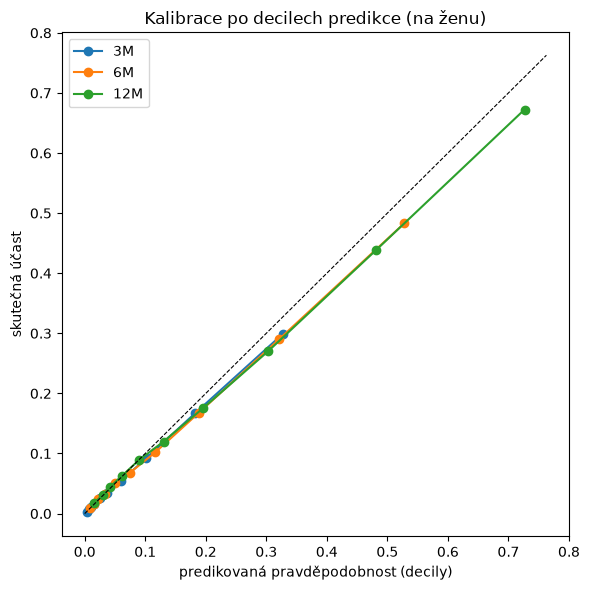

,účast,průměr predikce,AUROC,AUROC 95% CI,PR-AUC,log-loss,AUROC na pozvánku
horizont,,,,,,,
3M,0.071,0.077,0.832,0.829–0.834,0.278,0.204,0.832
6M,0.124,0.136,0.833,0.830–0.835,0.421,0.290,0.833
12M,0.192,0.207,0.834,0.832–0.836,0.568,0.367,0.834


In [4]:
rng = np.random.default_rng(0)
skup = test.groupby("PERSON_ID").indices
ids = np.array(list(skup))
wt = test.w.values
Y = test[LABELS].values
boot = []
for _ in range(200):
    ix = np.concatenate([skup[k] for k in rng.choice(ids, len(ids))])
    boot.append([roc_auc_score(Y[ix, j], F[ix, j], sample_weight=wt[ix]) for j in range(3)])
boot = np.array(boot)

rows = []
for j, (h, y) in enumerate(zip(HOR, LABELS)):
    yt, p = test[y].values, F[:, j]
    ci = np.percentile(boot[:, j], [2.5, 97.5])
    rows.append({"horizont": h, "účast": np.average(yt, weights=wt), "průměr predikce": np.average(p, weights=wt),
                 "AUROC": roc_auc_score(yt, p, sample_weight=wt), "AUROC 95% CI": f"{ci[0]:.3f}–{ci[1]:.3f}",
                 "PR-AUC": average_precision_score(yt, p, sample_weight=wt),
                 "log-loss": log_loss(yt, p, sample_weight=wt), "AUROC na pozvánku": roc_auc_score(yt, p)})
VYKON = pd.DataFrame(rows).set_index("horizont")
VYKON.to_csv(OUT / "vykon.csv")

HZ = pd.DataFrame([{"interval": nm, "v riziku": int(m.sum()),
                    "pozorovaný hazard": np.average(test.UDALOST[m] == k, weights=wt[m]),
                    "predikovaný hazard": np.average(H[m, k - 1], weights=wt[m])}
                   for k, nm in zip((1, 2, 3), INT) for m in [(test.UDALOST >= k).values]]).set_index("interval")
display(HZ.round(3))

fig, ax = plt.subplots(figsize=(6, 6))
for j, (h, y) in enumerate(zip(HOR, LABELS)):
    dec = pd.qcut(F[:, j], 10, labels=False, duplicates="drop")
    g = pd.DataFrame({"p": F[:, j] * wt, "y": test[y].values * wt, "w": wt}).groupby(dec).sum()
    ax.plot(g.p / g.w, g.y / g.w, "o-", label=h)
lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, lim], [0, lim], "k--", lw=0.8)
ax.set_xlabel("predikovaná pravděpodobnost (decily)"); ax.set_ylabel("skutečná účast")
ax.set_title("Kalibrace po decilech predikce (na ženu)"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "kalibrace.png", dpi=120); plt.show()
VYKON.round(3)

## 4 · Co model používá (SHAP)

Přesný TreeSHAP na 20 000 testovacích ženách (u každé jedna náhodná pozvánka z roku 2024, takže
každá žena váží stejně). Pro každý interval tytéž pozvánky s nastaveným číslem intervalu; hodnoty
jsou v log-odds hazardu. Kladný SHAP = vyšší šance přijít.

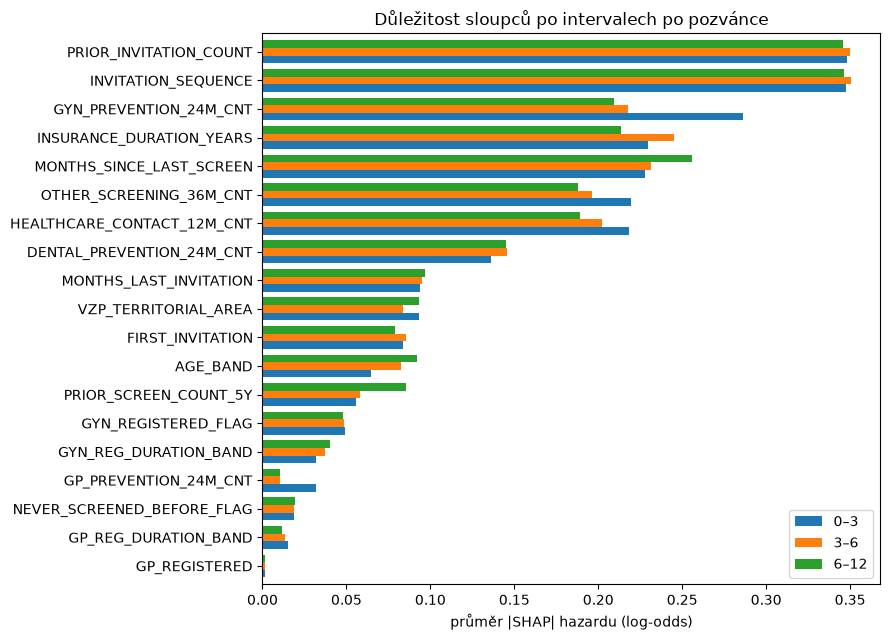

,0–3,3–6,6–12
PRIOR_INVITATION_COUNT,0.348,0.350,0.346
INVITATION_SEQUENCE,0.348,0.350,0.346
GYN_PREVENTION_24M_CNT,0.286,0.218,0.209
INSURANCE_DURATION_YEARS,0.230,0.245,0.213
MONTHS_SINCE_LAST_SCREEN,0.228,0.232,0.256
OTHER_SCREENING_36M_CNT,0.219,0.196,0.188
HEALTHCARE_CONTACT_12M_CNT,0.218,0.202,0.189
DENTAL_PREVENTION_24M_CNT,0.136,0.146,0.145
MONTHS_LAST_INVITATION,0.094,0.095,0.097
VZP_TERRITORIAL_AREA,0.094,0.083,0.093


In [5]:
vz = test.groupby("PERSON_ID").sample(1, random_state=0).sample(20_000, random_state=0)
SV, imp = {}, {}
for k, nm in zip((1, 2, 3), INT):
    SV[nm] = MW.get_feature_importance(Pool(vz[FEATURES].assign(INTERVAL=k), cat_features=CAT),
                                       type="ShapValues")[:, :len(FEATURES)]
    imp[nm] = np.abs(SV[nm]).mean(0)
IMP = pd.DataFrame(imp, index=FEATURES).sort_values("0–3", ascending=False)
IMP.round(3).to_csv(OUT / "shap_po_intervalech.csv")

fig, ax = plt.subplots(figsize=(9, 6.5))
IMP[::-1].plot.barh(ax=ax, width=0.8)
ax.set_xlabel("průměr |SHAP| hazardu (log-odds)"); ax.set_title("Důležitost sloupců po intervalech po pozvánce")
plt.tight_layout(); plt.savefig(OUT / "shap_dulezitost.png", dpi=120); plt.show()
IMP.round(3)

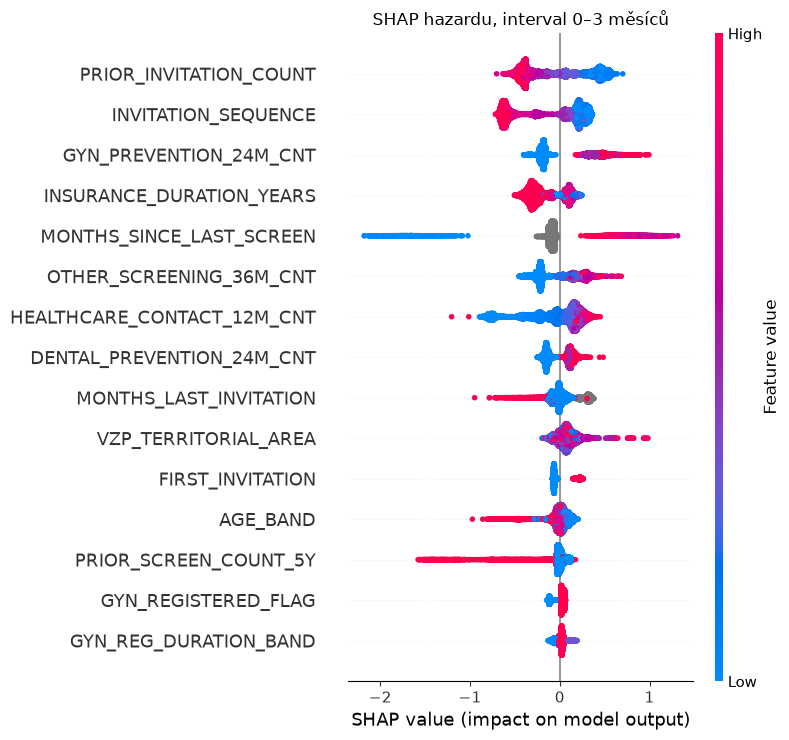

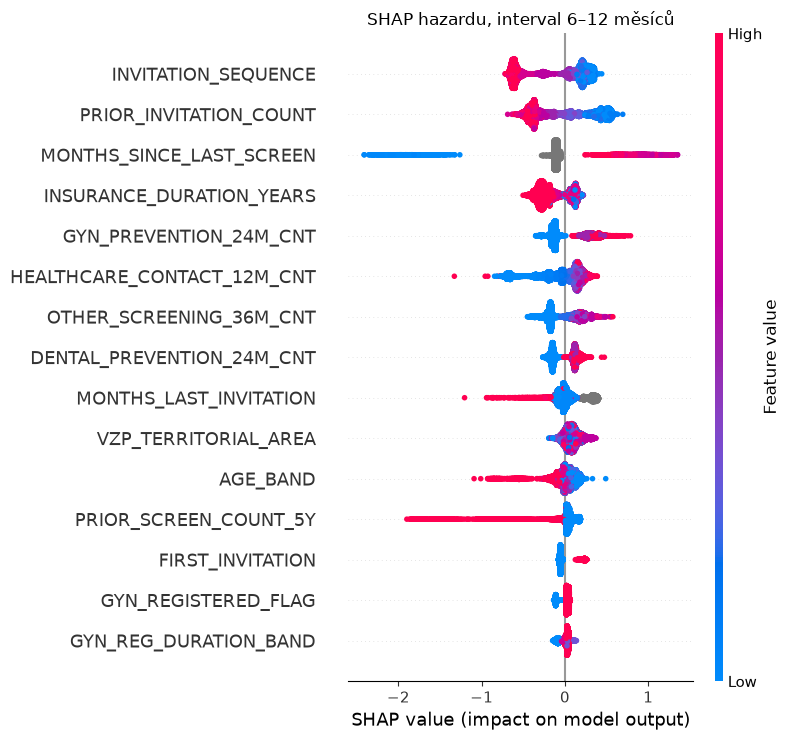

In [6]:
# beeswarm pro první a poslední interval; územní pracoviště převedené na kód jen kvůli barvě
Xv = vz[FEATURES].assign(VZP_TERRITORIAL_AREA=vz.VZP_TERRITORIAL_AREA.astype("category").cat.codes)
for nm in ["0–3", "6–12"]:
    shap.summary_plot(SV[nm], Xv, max_display=15, show=False)
    plt.title(f"SHAP hazardu, interval {nm} měsíců"); plt.tight_layout()
    plt.savefig(OUT / f"shap_beeswarm_{nm.replace('–', '_')}.png", dpi=120); plt.show()

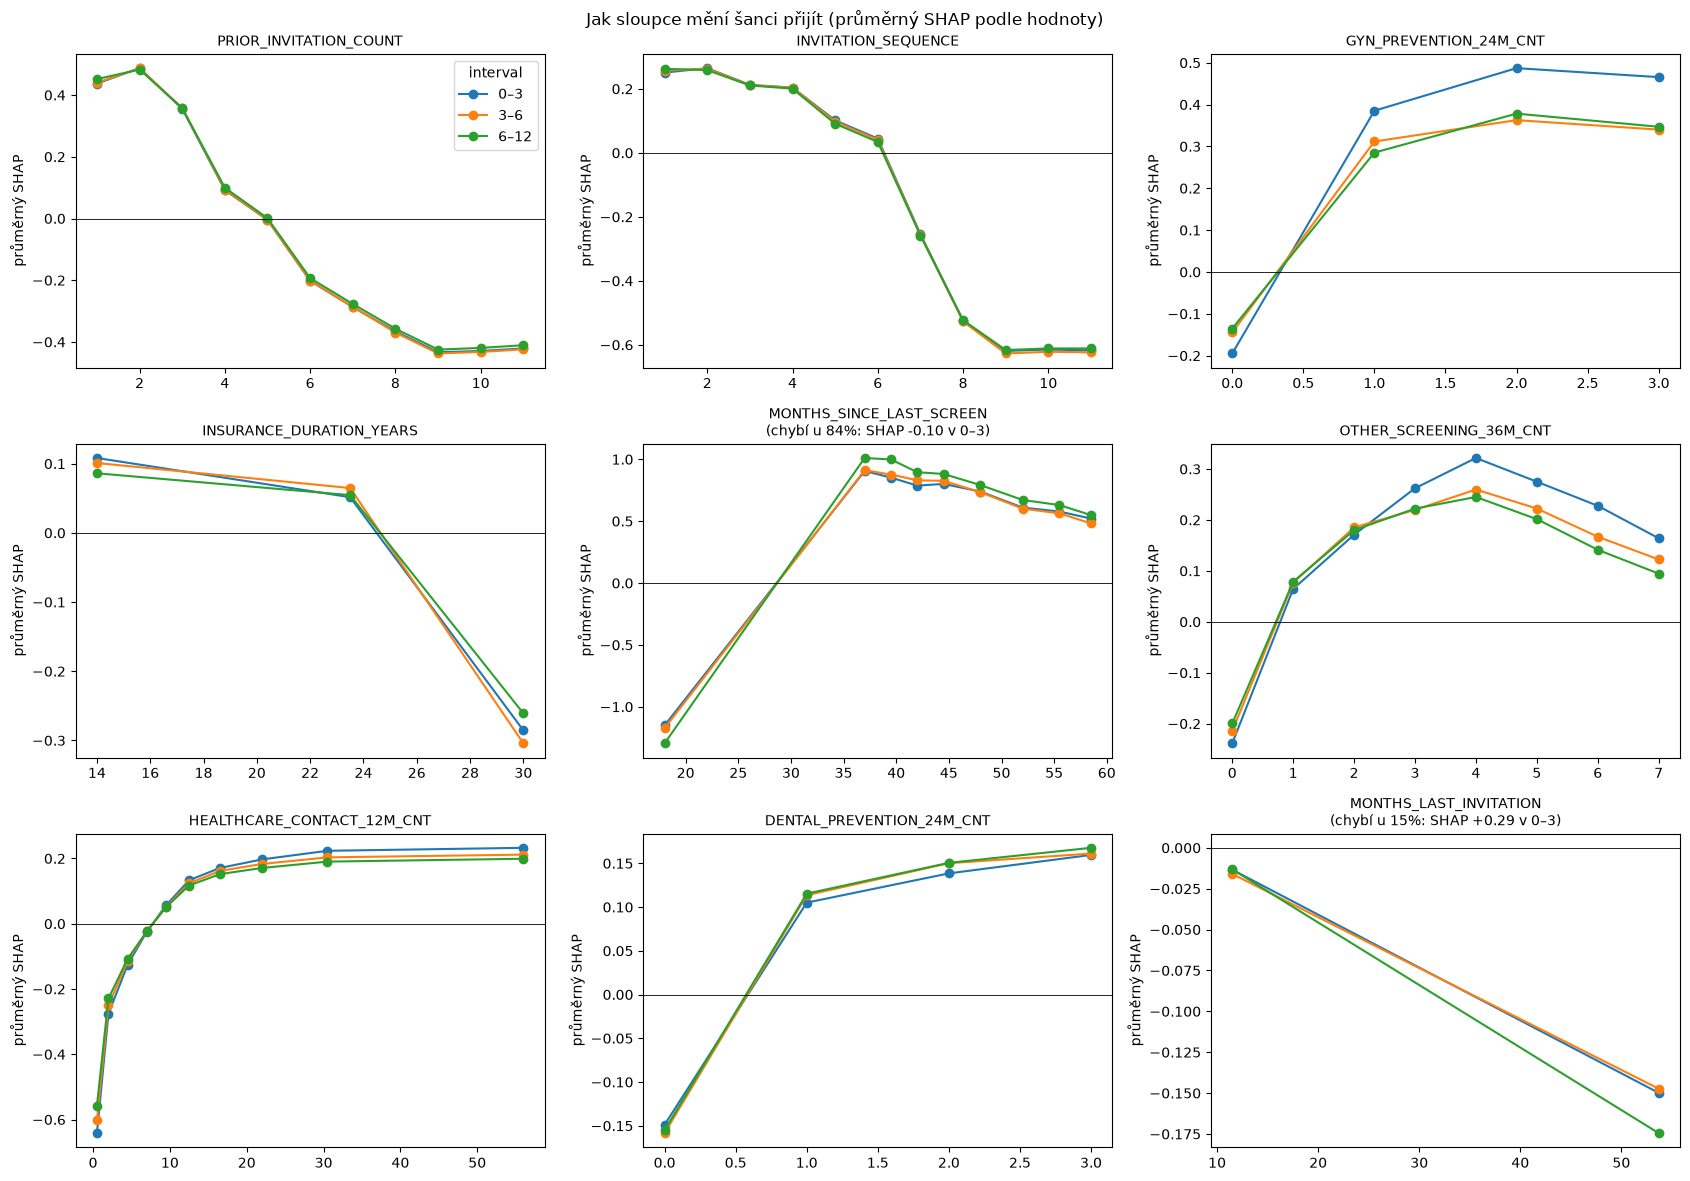

In [7]:
# průměrný SHAP podle hodnoty sloupce (spojité sloupce v decilech, horní 1 % oříznuté), čára = interval
TOP = [c for c in IMP.index if c not in CAT][:9]
fig, axes = plt.subplots(3, 3, figsize=(17, 12))
for ax, c in zip(axes.flat, TOP):
    j = FEATURES.index(c)
    v = vz[c].astype(float)
    ok = v.notna().values
    key = v.clip(upper=v.quantile(0.99))
    if key.nunique() > 15:
        b = pd.qcut(key, 10, duplicates="drop")
        key = b.cat.codes.map(dict(enumerate(b.cat.categories.mid))).astype(float)  # střed decilu, chybějící = NaN
    for nm in INT:
        pd.Series(SV[nm][ok, j]).groupby(key[ok].values).mean().plot(ax=ax, marker="o", label=nm)
    ax.axhline(0, color="k", lw=0.6); ax.set_ylabel("průměrný SHAP")
    t = c
    if not ok.all():
        t += f"\n(chybí u {1 - ok.mean():.0%}: SHAP {SV['0–3'][~ok, j].mean():+.2f} v 0–3)"
    ax.set_title(t, fontsize=10)
    if c == "AGE_BAND":
        ax.set_xlabel("dolní mez věkového pásma")
    elif c in BANDS:
        ax.set_xlabel("0 žádná · 1 <2 r · 2 2–5 let · 3 >5 let")
axes.flat[0].legend(title="interval")
plt.suptitle("Jak sloupce mění šanci přijít (průměrný SHAP podle hodnoty)"); plt.tight_layout()
plt.savefig(OUT / "shap_zavislosti.png", dpi=120); plt.show()

## 5 · Kde model funguje hůř: věk a známé vs. nové ženy (test 2024, na ženu)

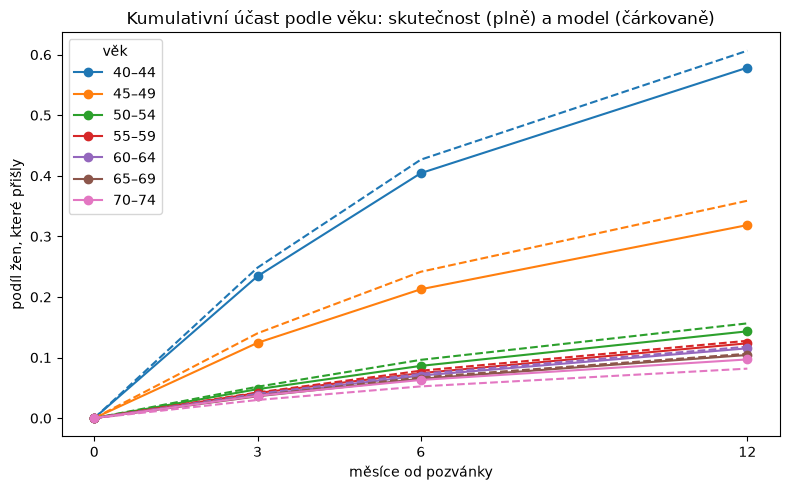

,žen,účast 3M,predikce 3M,AUROC 3M,účast 6M,predikce 6M,AUROC 6M,účast 12M,predikce 12M,AUROC 12M
skupina,,,,,,,,,,
věk 40–44,9361,0.234,0.248,0.689,0.404,0.427,0.695,0.578,0.606,0.734
věk 45–49,71128,0.124,0.140,0.782,0.213,0.242,0.789,0.319,0.359,0.806
věk 50–54,42529,0.048,0.052,0.780,0.086,0.096,0.778,0.143,0.156,0.766
věk 55–59,40867,0.041,0.042,0.818,0.074,0.078,0.809,0.123,0.128,0.800
věk 60–64,40983,0.038,0.040,0.823,0.070,0.073,0.810,0.115,0.118,0.797
věk 65–69,44662,0.036,0.037,0.824,0.065,0.067,0.814,0.104,0.106,0.804
věk 70–74,6936,0.037,0.030,0.813,0.063,0.052,0.808,0.097,0.082,0.796
nová,59153,0.182,0.200,0.728,0.312,0.339,0.736,0.455,0.488,0.767
známá (byla v učení),197313,0.037,0.040,0.790,0.068,0.075,0.777,0.113,0.123,0.767


In [8]:
t = test.assign(**{f"p_{h}": F[:, j] for j, h in enumerate(HOR)})
t["žena"] = np.where(test.PERSON_ID.isin(set(train.PERSON_ID)), "známá (byla v učení)", "nová")
rows = []
for col in ["AGE_BAND", "žena"]:
    for v, g in t.groupby(col):
        r = {"skupina": f"věk {v}–{v + 4}" if col == "AGE_BAND" else v, "žen": g.PERSON_ID.nunique()}
        for h, y in zip(HOR, LABELS):
            r[f"účast {h}"] = np.average(g[y], weights=g.w)
            r[f"predikce {h}"] = np.average(g[f"p_{h}"], weights=g.w)
            r[f"AUROC {h}"] = roc_auc_score(g[y], g[f"p_{h}"], sample_weight=g.w)
        rows.append(r)
POD = pd.DataFrame(rows).set_index("skupina")
POD.to_csv(OUT / "podskupiny.csv")

fig, ax = plt.subplots(figsize=(8, 5))
for i, (v, g) in enumerate(t.groupby("AGE_BAND")):
    ax.plot([0, 3, 6, 12], [0, *np.average(g[LABELS], axis=0, weights=g.w)], "-o", color=f"C{i}", label=f"{v}–{v + 4}")
    ax.plot([0, 3, 6, 12], [0, *np.average(g[[f"p_{h}" for h in HOR]], axis=0, weights=g.w)], "--", color=f"C{i}")
ax.set_xticks([0, 3, 6, 12]); ax.set_xlabel("měsíce od pozvánky"); ax.set_ylabel("podíl žen, které přišly")
ax.set_title("Kumulativní účast podle věku: skutečnost (plně) a model (čárkovaně)"); ax.legend(title="věk")
plt.tight_layout(); plt.savefig(OUT / "kumulativni_ucast_vek.png", dpi=120); plt.show()
POD.round(3)

## 6 · Kontrola: co změní vážení na ženu

Tentýž model hazardu bez vah (každá pozvánka váží stejně, jako v `vzp_hazard.ipynb`). Srovnání
výkonu (vážený i nevážený test) a pořadí důležitosti sloupců (průměr |SHAP| přes intervaly).

In [9]:
MI = model_hazardu(pp_tr, pp_va, na_zenu=False)
_, FI = predikce(MI, test)
rows = []
for j, (h, y) in enumerate(zip(HOR, LABELS)):
    yt = test[y].values
    rows.append({"horizont": h,
                 "AUROC na ženu: model na ženu": roc_auc_score(yt, F[:, j], sample_weight=wt),
                 "AUROC na ženu: model na pozvánku": roc_auc_score(yt, FI[:, j], sample_weight=wt),
                 "AUROC na pozvánku: model na ženu": roc_auc_score(yt, F[:, j]),
                 "AUROC na pozvánku: model na pozvánku": roc_auc_score(yt, FI[:, j]),
                 "průměr predikce na ženu: model na ženu": np.average(F[:, j], weights=wt),
                 "průměr predikce na ženu: model na pozvánku": np.average(FI[:, j], weights=wt)})
SROV = pd.DataFrame(rows).set_index("horizont")
SROV.to_csv(OUT / "vahy_zena_vs_pozvanka.csv")
imp_i = np.mean([np.abs(MI.get_feature_importance(Pool(vz[FEATURES].assign(INTERVAL=k), cat_features=CAT),
                                                  type="ShapValues")[:, :len(FEATURES)]).mean(0) for k in (1, 2, 3)], axis=0)
POR = pd.DataFrame({"|SHAP| model na ženu": IMP.mean(axis=1), "|SHAP| model na pozvánku": pd.Series(imp_i, index=FEATURES)})
POR["pořadí na ženu"] = POR.iloc[:, 0].rank(ascending=False).astype(int)
POR["pořadí na pozvánku"] = POR.iloc[:, 1].rank(ascending=False).astype(int)
POR = POR.sort_values("pořadí na ženu")
POR.round(3).to_csv(OUT / "shap_zena_vs_pozvanka.csv")
print(f"iterací: model na ženu {MW.get_best_iteration()}, model na pozvánku {MI.get_best_iteration()}")
display(SROV.T.round(4))
POR.round(3)

iterací: model na ženu 603, model na pozvánku 750


horizont,3M,6M,12M
AUROC na ženu: model na ženu,0.8317,0.8325,0.8340
AUROC na ženu: model na pozvánku,0.8350,0.8356,0.8362
AUROC na pozvánku: model na ženu,0.8317,0.8325,0.8340
AUROC na pozvánku: model na pozvánku,0.8350,0.8356,0.8362
průměr predikce na ženu: model na ženu,0.0770,0.1358,0.2075
průměr predikce na ženu: model na pozvánku,0.0682,0.1187,0.1847


,|SHAP| model na ženu,|SHAP| model na pozvánku,pořadí na ženu,pořadí na pozvánku
INVITATION_SEQUENCE,0.348,0.357,1,2
PRIOR_INVITATION_COUNT,0.348,0.372,2,1
MONTHS_SINCE_LAST_SCREEN,0.238,0.263,3,3
GYN_PREVENTION_24M_CNT,0.238,0.263,4,4
INSURANCE_DURATION_YEARS,0.229,0.137,5,7
HEALTHCARE_CONTACT_12M_CNT,0.203,0.211,6,6
OTHER_SCREENING_36M_CNT,0.201,0.214,7,5
DENTAL_PREVENTION_24M_CNT,0.142,0.127,8,8
MONTHS_LAST_INVITATION,0.095,0.049,9,13
VZP_TERRITORIAL_AREA,0.090,0.100,10,9


## Interpretace

**Přehled (oddíl 1).** Účast je od roku 2021 stabilní (do 12 měsíců 19–20 % na pozvánku); rok 2020
je nižší (17,8 %), pravděpodobně kvůli covidu. Rozdíl mezi účastí na pozvánku a na ženu je velký,
protože ženy, které nechodí, dostávají pozvánku každý rok a v datech se opakují.

**Výkon a kalibrace (oddíl 3).** Hazard je nejvyšší hned po pozvánce (7,1 % za 0–3 měsíce, 5,7 % za
3–6); interval 6–12 měsíců má 7,8 % za půl roku, tedy asi polovinu na čtvrtletí. Model žen váženě
**nadhodnocuje účast o 8–14 % relativně** v každém intervalu, nejvíc u žen 45–49 let (24,2 %
predikce proti 21,3 % do 6 měsíců) a u nových žen (33,9 % proti 31,2 %); u žen 70–74 let naopak
podhodnocuje. Pořadí žen (AUROC) to nemění, pro plánování kapacit by ale predikci bylo třeba
přepočítat (rekalibrovat), nebo použít model na pozvánku.

**Co model používá (oddíl 4).** Hodnoty SHAP jsou v log-odds; +0,5 zhruba znamená o 65 % vyšší šanci.
* **Historie pozvánek.** Počet pozvánek 1–3 šanci zvyšuje, od 6 snižuje (až −0,4); pořadové číslo
  pozvánky od 7 snižuje (až −0,6); od 9 se už nic nemění. `PRIOR_INVITATION_COUNT` a `INVITATION_SEQUENCE` se shodují v 85–92 %
  řádků (korelace 0,96); model mezi ně důležitost dělí libovolně, je to jeden faktor.
* **Měsíce od posledního screeningu.** Do 24 měsíců silně snižuje (SHAP kolem −1,2: žena ještě není
  na řadě, pozvánka přišla brzy), 36–40 měsíců nejvíc zvyšuje (+0,9) a s delší dobou slábne. Ženy
  bez screeningu za 5 let (84 %) jsou mírně pod průměrem.
* **Preventivní gynekologie.** Aspoň jedna prohlídka za 24 měsíců šanci výrazně zvyšuje, nejvíc
  v prvních 3 měsících po pozvánce (SHAP +0,4 až +0,5 proti +0,3 až +0,4 později). Odpovídá okresnímu
  zjištění o „gynekologickém kanálu“: gynekolog ženu pravděpodobně pošle na mamograf hned.
* **Kontakty se zdravotnictvím.** Ženy s 0–5 kontakty za rok mají šanci výrazně nižší (až −0,6),
  nad zhruba 20 kontaktů je efekt nasycený. Málo kontaktů = žena, kterou zdravotnictví nevidí.
* **Jiné screeningy a zubní prevence.** Kdo chodí na prevenci jinam, chodí i na mamograf. U jiných
  screeningů je efekt nejsilnější při 3–5 za 3 roky a v prvních 3 měsících.
* **Délka pojištění.** Ženy pojištěné u VZP od jejího vzniku (kolem 30 let) chodí méně než ženy,
  které k VZP přešly později. Příčina není jasná (přechod mezi pojišťovnami může znamenat aktivnější
  péči o zdraví); při vážení na ženu tento sloupec stoupá z 7. na 5. místo.
* **Měsíce od minulé pozvánky.** Delší odstup šanci snižuje, první pozvánka (hodnota chybí) zvyšuje.
* **Málo nebo nic:** věkové pásmo (v souhrnu malé, ale ženy 40–44 chodí nejvíc, viz oddíl 5),
  územní pracoviště, délka registrace u gynekologa a vše kolem praktického lékaře.
* **V čase** je většina vlivů stejná; brzy po pozvánce působí hlavně gynekologie, jiné screeningy
  a kontakty se zdravotnictvím, měsíce od posledního screeningu mírně sílí později.

**Kde model funguje hůř (oddíl 5).** Ženy 40–44 let (pozvané kolem 45. narozenin) chodí nejvíc
(58 % do 12 měsíců), ale model je u nich nejslabší (AUROC 0,69–0,73): nemají historii screeningu
ani pozvánek, takže model o nich ví málo. Podobně nové ženy (AUROC 0,73–0,77) proti známým
(0,77–0,79). Právě u prvních pozvánek by pomohly další údaje (např. okresní dostupnost, socioekonomika).

**Vážení na ženu (oddíl 6).** Model na pozvánku má AUROC o 0,002–0,003 vyšší a je lépe kalibrovaný
(18,5 % proti skutečným 19,2 % do 12 měsíců). Vážení posune učení k ženám s málo pozvánkami, které
chodí víc, takže model očekává vyšší účast, než jakou má skutečný proud pozvánek, ve kterém jsou
opakovaně zvané ženy zastoupené. Pořadí důležitosti se mění jen u několika sloupců: při vážení na
ženu stoupá délka pojištění (7. → 5.), měsíce od minulé pozvánky (13. → 9.) a první pozvánka
(15. → 11.); klesá počet screeningových kódů za 5 let (10. → 13.) a délka registrace u gynekologa
(11. → 15.).

**Doporučení.** Pro skórování pozvánek na další rok použít model na pozvánku; pro výklad, co
rozhoduje u typické ženy, model na ženu. Oba se shodují v tom podstatném: ženy, které chodí na jinou
prevenci a ke gynekologovi, přijdou; opakovaně zvané ženy bez kontaktu se zdravotnictvím ne.
Kdo přijde **díky** intervenci, ale model neřekne; na to je potřeba experiment.

## Poznámky a omezení

* **Cílová proměnná není jen screening.** Kódy štítků (89178, 89223, 89225, 89314, 89510, 89814)
  zahrnují i doplňující snímky, ultrazvuk a biopsii. `PRIOR_SCREEN_COUNT_5Y` počítá vykázané kódy,
  ne screeningy (jeden screening je obvykle 2 kódy).
* **Překryv oken u 12 měsíců.** Pozvánky jsou od sebe aspoň 8 měsíců, takže jedna mamografie může
  započítat úspěch dvou po sobě jdoucích pozvánek (asi 1,5 % kladných štítků do 12 měsíců).
* **`VZP_TERRITORIAL_AREA` je územní pracoviště VZP, ne okres** (75 hodnot, velikosti neodpovídají
  okresům); okresní ukazatele na něj spolehlivě napojit nejde. Věk 75+ v datech není.
* **V datech nejsou nově pojištěné ženy** (jen nepřetržitě pojištěné 2015–2025), tedy ani
  příchozí z Ukrajiny po roce 2022.
* **SHAP popisuje model, ne příčiny.** Model předpovídá, kdo přijde, ne kdo přijde díky intervenci;
  o účinku intervencí rozhodne experiment (`docs/interventions.md`).